In [192]:
import torch 
info=torch.load('/Users/robinhu/Desktop/torchdata/totaldataset.pt')['info']
feature=torch.load('/Users/robinhu/Desktop/torchdata/totaldataset.pt')['feature']
label=torch.load('/Users/robinhu/Desktop/torchdata/totaldataset.pt')['label']

In [3]:
def preprocessing(info,feature,label):
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    X_trainval, X_test, y_trainval, y_test,info_trainval,info_test= train_test_split(
        feature, label,info, test_size=0.2, random_state=42, stratify=label )
    X_train, X_val, y_train, y_val,info_train,info_val= train_test_split(
    X_trainval, y_trainval, info_trainval,test_size=0.25, random_state=42, stratify=y_trainval)
    X_train_np = X_train.numpy()  
    X_val_np = X_val.numpy()
    X_test_np = X_test.numpy()
    original_shape_train = X_train_np.shape  
    original_shape_val = X_val_np.shape  
    original_shape_test = X_test_np.shape  
    X_train_flat = X_train_np.reshape(original_shape_train[0], -1)  
    X_val_flat = X_val_np.reshape(X_val_np.shape[0], -1)
    X_test_flat = X_test_np.reshape(X_test_np.shape[0], -1)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_flat)
    X_train_reverse= X_train_scaled.reshape(original_shape_train)
    X_val_scaled= scaler.transform(X_val_flat)
    X_val_reverse = X_val_scaled.reshape(original_shape_val)
    X_test_scaled = scaler.transform(X_test_flat)
    X_test_reverse=X_test_scaled.reshape(original_shape_test)
    return X_train_reverse,X_val_reverse,X_test_reverse,info_train,info_val,info_test,y_train,y_val,y_test,scaler

In [193]:
feature_train_new,feature_val_new,feature_test_new,info_train,info_val,info_test,y_train,y_val,y_test,scaler=preprocessing(info,feature,label)

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class OptimizedCNNLSTMClassifier(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2)), 
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2)), 
            
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2)),  
            
      
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, None))  # [256, 1, 77]
        )
        
        # LSTM part
        # [batch, 77, 256]
        self.lstm = nn.LSTM(
            input_size=256,          
            hidden_size=128,         
            num_layers=2,           
            bidirectional=True,      
            batch_first=True,        
            dropout=dropout_rate     
        )
        
        # Attention
        self.attention = nn.Sequential(
            nn.Linear(256, 128),     
            nn.Tanh(),               
            nn.Linear(128, 1)        
        )

        
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(256, 128),     
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 1)        
        )
        
        self._init_weights()
        
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LSTM):
                for name, param in m.named_parameters():
                    if 'weight' in name:
                        nn.init.orthogonal_(param)
                    elif 'bias' in name:
                        nn.init.zeros_(param)
    
    def forward(self, x):
        x = x.unsqueeze(1)
        cnn_out = self.cnn(x)
        cnn_out = cnn_out.squeeze(2)
        cnn_out = cnn_out.permute(0, 2, 1)
        lstm_out, _ = self.lstm(cnn_out)
        attention_weights = F.softmax(self.attention(lstm_out), dim=1)
        weighted_output = torch.sum(attention_weights * lstm_out, dim=1)
        logits = self.classifier(weighted_output)
        
        return logits
    
    def predict_proba(self, x, threshold=0.5):
        with torch.no_grad():
            self.eval()  
            logits = self.forward(x)
            probabilities = torch.sigmoid(logits)  
            return probabilities
    
    def predict(self, x, threshold=0.5):
        probabilities = self.predict_proba(x)
        predictions = (probabilities > threshold).float()
        return predictions
    
    def get_attention_map(self, x):
        with torch.no_grad():
            self.eval()
            x = x.unsqueeze(1)
            cnn_out = self.cnn(x)
            cnn_out = cnn_out.squeeze(2).permute(0, 2, 1)
            lstm_out, _ = self.lstm(cnn_out)
            attention_weights = F.softmax(self.attention(lstm_out), dim=1)
            return attention_weights.squeeze(-1)  # [batch, 77]

In [170]:
def train_model_direct_with_early_stop(model, X_train, y_train, X_val, y_val, 
                                      num_epochs=50, batch_size=64, lr=0.0003,
                                      patience=15, min_delta=0.001):

    
    device = torch.device('mps')
    model = model.to(device)
    
    X_train_tensor = torch.FloatTensor(X_train).to(device)
    y_train_tensor = y_train.float().to(device).unsqueeze(1)
    X_val_tensor = torch.FloatTensor(X_val).to(device)
    y_val_tensor = y_val.float().to(device).unsqueeze(1)
    
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': [],
        'train_auc': [], 'val_auc': []
    }
    
    best_val_loss = float('inf')
    best_val_acc = 0.0
    best_model_state = None
    patience_counter = 0
    best_epoch = 0
    
    n_samples = len(X_train_tensor)
    n_batches = (n_samples + batch_size - 1) // batch_size
    
    for epoch in range(num_epochs):
        start_time = time.time()
        model.train()
        train_loss = 0.0
        all_train_preds, all_train_labels, all_train_probs = [], [], []
        
        indices = torch.randperm(n_samples)
        
        for batch_idx in range(n_batches):
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_samples)
            batch_indices = indices[start_idx:end_idx]
            
            batch_x = X_train_tensor[batch_indices]
            batch_y = y_train_tensor[batch_indices]
            
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_loss += loss.item() * len(batch_indices)
            
            with torch.no_grad():
                probs = torch.sigmoid(logits)
                preds = (probs > 0.5).float()
                all_train_preds.extend(preds.cpu().numpy())
                all_train_labels.extend(batch_y.cpu().numpy())
                all_train_probs.extend(probs.cpu().numpy())
        
        
        model.eval()
        val_loss = 0.0
        all_val_preds, all_val_labels, all_val_probs = [], [], []
        
        with torch.no_grad():
            n_val_samples = len(X_val_tensor)
            n_val_batches = (n_val_samples + batch_size - 1) // batch_size
            
            for batch_idx in range(n_val_batches):
                start_idx = batch_idx * batch_size
                end_idx = min((batch_idx + 1) * batch_size, n_val_samples)
                
                batch_x = X_val_tensor[start_idx:end_idx]
                batch_y = y_val_tensor[start_idx:end_idx]
                
                logits = model(batch_x)
                loss = criterion(logits, batch_y)
                val_loss += loss.item() * len(batch_x)
                
                probs = torch.sigmoid(logits)
                preds = (probs > 0.5).float()
                all_val_preds.extend(preds.cpu().numpy())
                all_val_labels.extend(batch_y.cpu().numpy())
                all_val_probs.extend(probs.cpu().numpy())
        
        
        all_train_labels = np.array(all_train_labels).flatten()
        all_train_preds = np.array(all_train_preds).flatten()
        all_train_probs = np.array(all_train_probs).flatten()
        
        all_val_labels = np.array(all_val_labels).flatten()
        all_val_preds = np.array(all_val_preds).flatten()
        all_val_probs = np.array(all_val_probs).flatten()
        
        train_acc = accuracy_score(all_train_labels, all_train_preds)
        val_acc = accuracy_score(all_val_labels, all_val_preds)
        train_f1 = f1_score(all_train_labels, all_train_preds)
        val_f1 = f1_score(all_val_labels, all_val_preds)
        train_auc = roc_auc_score(all_train_labels, all_train_probs)
        val_auc = roc_auc_score(all_val_labels, all_val_probs)
        
        avg_train_loss = train_loss / n_samples
        avg_val_loss = val_loss / n_val_samples
        
        scheduler.step(avg_val_loss)
        
        loss_improved = avg_val_loss < best_val_loss - min_delta
        acc_improved = val_acc > best_val_acc + 0.002  
        
        if loss_improved or acc_improved:
            
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
            if val_acc > best_val_acc:
                best_val_acc = val_acc
            
            best_model_state = model.state_dict().copy()
            best_epoch = epoch
            patience_counter = 0  
            
            torch.save(model.state_dict(), f'best_model_epoch{epoch}.pth')
        else:
            patience_counter += 1
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)
        history['train_auc'].append(train_auc)
        history['val_auc'].append(val_auc)
        
        epoch_time = time.time() - start_time
        lr_current = optimizer.param_groups[0]['lr']
        
        print(f"Epoch {epoch+1:03d}/{num_epochs} | "
              f"Time: {epoch_time:.1f}s | LR: {lr_current:.6f} | "
              f"Train Loss: {avg_train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} Acc: {val_acc:.4f} | "
              f"Patience: {patience_counter}/{patience}")
        
        if patience_counter >= patience:
            break
    
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    return model, history

In [173]:
def evaluate_model_direct(model, X_test, y_test, batch_size=32):
    device = torch.device('mps')
    model = model.to(device)
    model.eval()
    
    X_test_tensor = torch.FloatTensor(X_test).to(device)
    y_test_tensor = y_test.float().to(device).unsqueeze(1)
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        n_samples = len(X_test_tensor)
        n_batches = (n_samples + batch_size - 1) // batch_size
        
        for batch_idx in range(n_batches):
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_samples)
            
            batch_x = X_test_tensor[start_idx:end_idx]
            batch_y = y_test_tensor[start_idx:end_idx]
            
            logits = model(batch_x)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    all_labels = np.array(all_labels).flatten()
    all_preds = np.array(all_preds).flatten()
    all_probs = np.array(all_probs).flatten()
    
    from sklearn.metrics import classification_report, confusion_matrix
    
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)
    
    print("Results on Testing Data\n:")
    print(f"sample number: {len(all_labels)}")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("\nReport:")
    print(classification_report(all_labels, all_preds, 
                                target_names=['Style0', 'Style1']))
    
    cm = confusion_matrix(all_labels, all_preds)
    print("Confusion Matrix:")
    print(f"            Predicted")
    print(f"            Style0  Style1")
    print(f"Actual Style0  {cm[0,0]:4d}    {cm[0,1]:4d}")
    print(f"       Style1  {cm[1,0]:4d}    {cm[1,1]:4d}")
    
    return {
        'accuracy': acc,
        'f1': f1,
        'auc': auc,
        'predictions': all_preds,
        'probabilities': all_probs,
        'labels': all_labels
    }

In [159]:
def plot_training_history(history):
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    axes = axes.reshape(2, 3)

    axes[0, 1].plot(history['train_acc'], label='Train Acc')
    axes[0, 1].plot(history['val_acc'], label='Val Acc')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].set_title('Training and Validation Accuracy')
    axes[0, 1].legend()
    axes[0, 1].grid(True)
    
    axes[0, 2].plot(history['train_f1'], label='Train F1')
    axes[0, 2].plot(history['val_f1'], label='Val F1')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('F1 Score')
    axes[0, 2].set_title('Training and Validation F1 Score')
    axes[0, 2].legend()
    axes[0, 2].grid(True)
    
    axes[1, 0].plot(history['train_auc'], label='Train AUC')
    axes[1, 0].plot(history['val_auc'], label='Val AUC')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('AUC')
    axes[1, 0].set_title('Training and Validation AUC')
    axes[1, 0].legend()
    axes[1, 0].grid(True)
    
    if 'train_loss' in history and 'val_loss' in history:
        axes[0, 0].plot(history['train_loss'], label='Train Loss')
        axes[0, 0].plot(history['val_loss'], label='Val Loss')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].set_title('Training and Validation Loss')
        axes[0, 0].legend()
        axes[0, 0].grid(True)
    
    for i in range(2):
        for j in range(3):
            if not axes[i, j].has_data():
                axes[i, j].set_visible(False)
    
    plt.tight_layout()
    plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

In [164]:
def main_direct():
    BATCH_SIZE = 64
    NUM_EPOCHS = 50
    LEARNING_RATE = 0.0003
    DROPOUT_RATE = 0.5
    model = OptimizedCNNLSTMClassifier(dropout_rate=DROPOUT_RATE)

    trained_model, history = train_model_direct_with_early_stop(
        model=model,
        X_train=feature_train_new,
        y_train=y_train, 
        X_val=feature_val_new,
        y_val=y_val,      
        num_epochs=NUM_EPOCHS,
        batch_size=BATCH_SIZE,
        lr=LEARNING_RATE
    )
    
    print("Explanatory Analysis\n")
    plot_training_history(history)
    
    print("\nEstimation on Testing Data")
    test_results = evaluate_model_direct(
        model=trained_model,
        X_test=feature_test_new,
        y_test=y_test,    
        batch_size=BATCH_SIZE
    )
    
    torch.save({
        'model_state_dict': trained_model.state_dict(),
        'history': history,
        'test_results': test_results,
        'model_config': {
            'dropout_rate': DROPOUT_RATE,
            'input_shape': (80, 616)
        }
    }, 'final_model_direct.pth')

    print(f'Your model has been trained and saved successfully.')
    
    return trained_model, history, test_results

优化后的二分类模型初始化完成，dropout_rate=0.5
Epoch 001/50 | Time: 14.2s | LR: 0.000300 | Train Loss: 0.4735 Acc: 0.7885 | Val Loss: 1.2942 Acc: 0.5357 | Patience: 0/15
Epoch 002/50 | Time: 13.1s | LR: 0.000300 | Train Loss: 0.2577 Acc: 0.9067 | Val Loss: 0.3546 Acc: 0.8760 | Patience: 0/15
Epoch 003/50 | Time: 13.2s | LR: 0.000300 | Train Loss: 0.1959 Acc: 0.9317 | Val Loss: 0.1694 Acc: 0.9485 | Patience: 0/15
Epoch 004/50 | Time: 13.4s | LR: 0.000300 | Train Loss: 0.1393 Acc: 0.9473 | Val Loss: 0.2108 Acc: 0.9228 | Patience: 1/15
Epoch 005/50 | Time: 13.3s | LR: 0.000300 | Train Loss: 0.1535 Acc: 0.9426 | Val Loss: 0.3407 Acc: 0.8795 | Patience: 2/15
Epoch 006/50 | Time: 13.4s | LR: 0.000300 | Train Loss: 0.0918 Acc: 0.9661 | Val Loss: 0.3357 Acc: 0.9006 | Patience: 3/15
Epoch 007/50 | Time: 13.4s | LR: 0.000300 | Train Loss: 0.0901 Acc: 0.9731 | Val Loss: 0.2155 Acc: 0.9462 | Patience: 4/15
Epoch 008/50 | Time: 13.6s | LR: 0.000300 | Train Loss: 0.0623 Acc: 0.9785 | Val Loss: 0.1508 Acc: 0.9485 |

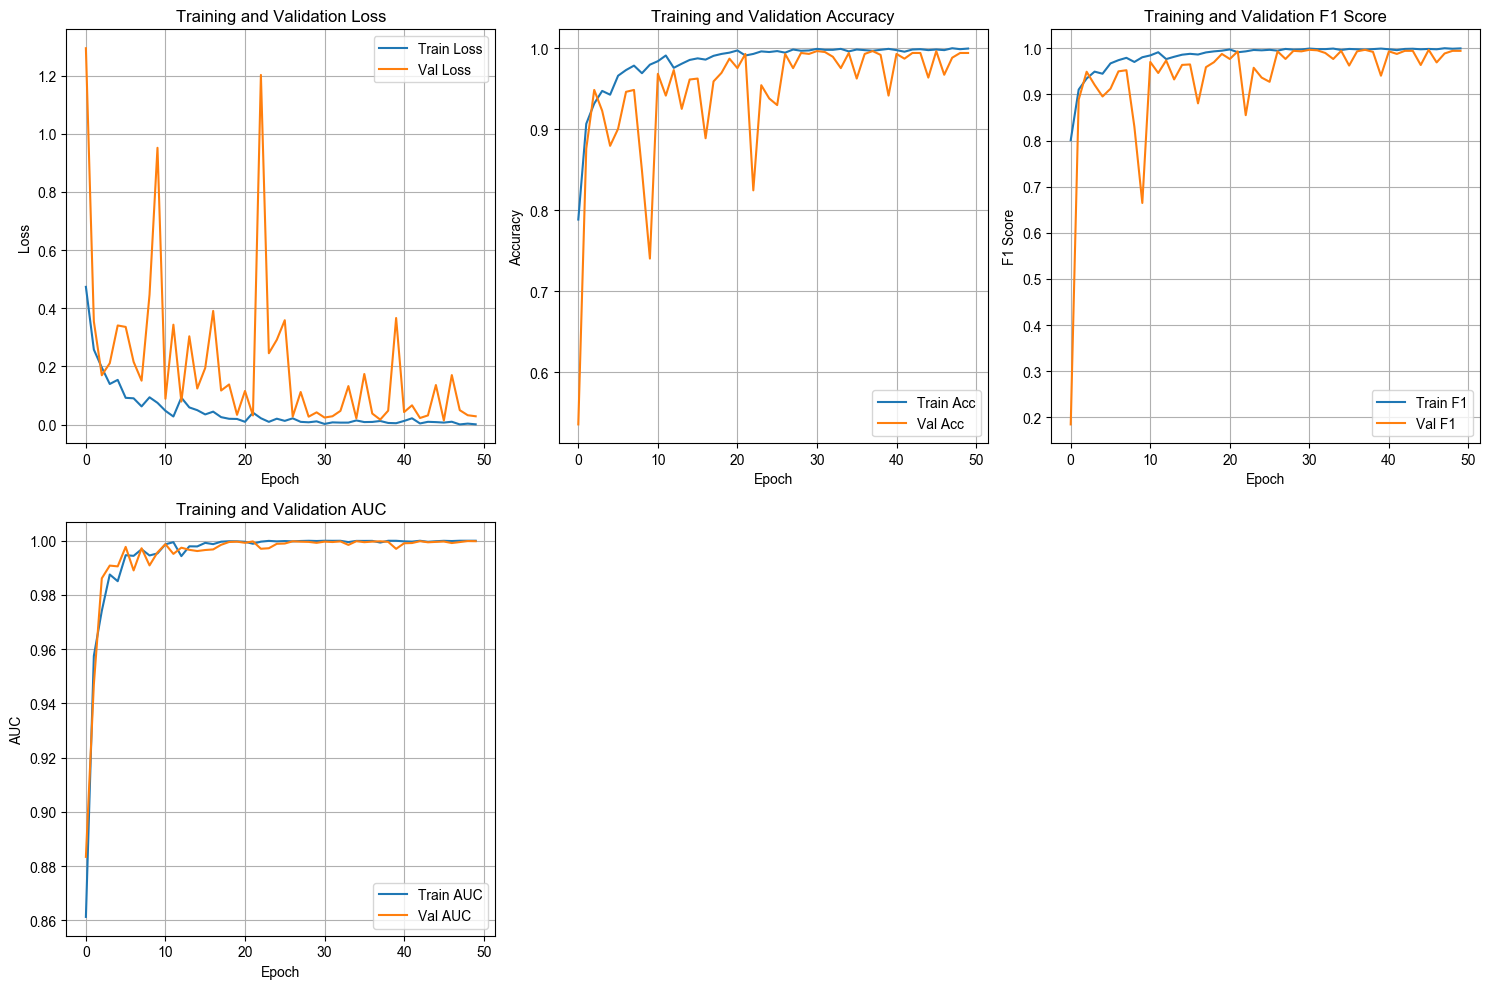


Estimation on Testing Data
Results on Testing Data
:
sample number: 855
Accuracy: 0.9953
F1 Score: 0.9955
AUC: 0.9997

Report:
              precision    recall  f1-score   support

      Style0       0.99      1.00      1.00       413
      Style1       1.00      0.99      1.00       442

    accuracy                           1.00       855
   macro avg       1.00      1.00      1.00       855
weighted avg       1.00      1.00      1.00       855

Confusion Matrix:
            Predicted
            Style0  Style1
Actual Style0   413       0
       Style1     4     438
Your model has been trained and saved successfully.


In [174]:
trained_model, history, test_results = main_direct()

In [194]:
def evaluate_on_test_set(model, X_test, y_test):
    device = next(model.parameters()).device
    model.eval()
    X_test_t = torch.FloatTensor(X_test).to(device)
    y_test_t = y_test.float().to(device).unsqueeze(1)
    all_preds = []
    all_probs = []
    all_labels = []
    
    with torch.no_grad():
        batch_size = 128
        for i in range(0, len(X_test_t), batch_size):
            batch_x = X_test_t[i:i+batch_size]
            batch_y = y_test_t[i:i+batch_size]
            
            logits = model(batch_x)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()
            
            all_preds.append(preds.cpu())
            all_probs.append(probs.cpu())
            all_labels.append(batch_y.cpu())
    
    all_preds = torch.cat(all_preds).numpy().flatten()
    all_probs = torch.cat(all_probs).numpy().flatten()
    all_labels = torch.cat(all_labels).numpy().flatten()
    
    
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)
    print(f"sample number : {len(all_labels)}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print("\nReport:")
    print(classification_report(all_labels, all_preds, target_names=['Class 0', 'Class 1']))
    
    
    cm = confusion_matrix(all_labels, all_preds)
    print("Confusion Matrix")
    print(f"              Prediction")
    print(f"                 0      1")
    print(f"Label 0  |   {cm[0,0]:5d}   {cm[0,1]:5d}")
    print(f"      1  |   {cm[1,0]:5d}   {cm[1,1]:5d}")
    
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'predictions': all_preds,
        'probabilities': all_probs,
        'labels': all_labels
    }

test_results = evaluate_on_test_set(trained_model, feature_test_new, y_test)

sample number : 855
Accuracy: 0.9953
Precision: 1.0000
Recall: 0.9910
F1 Score: 0.9955
AUC: 0.9997

Report:
              precision    recall  f1-score   support

     Class 0       0.99      1.00      1.00       413
     Class 1       1.00      0.99      1.00       442

    accuracy                           1.00       855
   macro avg       1.00      1.00      1.00       855
weighted avg       1.00      1.00      1.00       855

Confusion Matrix
              Prediction
                 0      1
Label 0  |     413       0
      1  |       4     438


In [446]:
torch.save({'transformed_mel':transformed_tensor},'/Users/robinhu/Desktop/torchdata/CNNLSTM_transformed_tensor_jazz.pt')

In [544]:
import joblib
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']